In [1]:
%pip install pandas gensim tensorflow tensorflow[and-cuda] scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


# Carga Inicial de Datos

[Sentiment140](https://huggingface.co/datasets/stanfordnlp/sentiment140) es un conjunto de datos de gran escala para la clasificación del sentimiento en Twitter, que contiene 1,6 millones de tuits etiquetados automáticamente mediante emoticonos como forma de supervisión distante (*distant supervision*).

Los tuits que contienen emoticonos positivos (p. ej., :), :-)) se etiquetan como positivos (`sentiment=4`), mientras que los que contienen emoticonos negativos (p. ej., :(, :-() se etiquetan como negativos (`sentiment=0`). Este conjunto de datos se utiliza ampliamente como referencia para la clasificación de sentimientos binaria y multiclase en la investigación sobre procesamiento del lenguaje natural (PLN).



In [2]:
import io, zipfile, urllib.request
import re, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow import keras
from tensorflow.keras import layers

_URL = "http://help.sentiment140.com/home"
_DATA_URL = "https://cs.stanford.edu/people/alecmgo/trainingandtestdata.zip"

_TRAIN_FILE_NAME = "training.1600000.processed.noemoticon.csv"

# Descargamos el zip con el Dataset
with urllib.request.urlopen(_DATA_URL) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))

I0000 00:00:1794903144.640608   81899 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794903144.669810   81899 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794903145.497691   81899 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


# Pre-processing

Partimos de texto generalmente muy informal con abreviaciones, faltas de ortografia, #, @ de usuarios y un monton de palabras y abreviaciones polisemicas.

Por lo que si queremos crear un clasificador debemos de limpiar los datos lo maximo posible. Esto es lo que hemos hecho:

- **Unificamos el formato del texto**: lo pasamos a minúsculas, decodificamos las entidades HTML y normalizamos los apóstrofos.

- **Sustituimos los elementos variables por tokens genéricos**: URLs, menciones, hashtags, números, caras y corazones pasan a ser `<url>`, `<user>`, `<hashtag>`, `<num>`, `<happyface>`, `<sadface>` y `<heart>`. Lo que nos interesa es que aparecen, no su contenido concreto.

- **Expandimos contracciones y abreviaturas** (`can't` → `can not`, `dont` → `do not`, `btw` → `by the way`). Así las negaciones quedan como palabras sueltas y el modelo puede aprenderlas.

- **Reducimos la intensidad sin perderla**: acortamos las letras y exclamaciones repetidas (`soooo` → `soo`, `!!!!` → `!!`) en lugar de eliminarlas.

- **Eliminamos el resto de símbolos** y dividimos el texto en tokens, conservando `!` y `?` porque aportan carga emocional.



> Dicho esto hay problemas que **no vamos a poder corregir**, como la **polisemia** de abreviaciones y palabras, **faltas de ortografía**.



In [3]:

cols = ["target", "id", "date", "flag", "user", "text"]
df = pd.read_csv(zf.open(_TRAIN_FILE_NAME),
                 encoding="latin-1", header=None, names=cols)

print(df.head())

# Nos quedamos solo con target y text. Convertimos el sentimiento
# que en el dataset es 0 = negativo, 4 = positivo a una c.binaria
df = df[["target", "text"]].copy()
df["label"] = (df["target"] == 4).astype(int)   # 0 = negativo, 1 = positivo


   target          id                          date      flag  \
0       0  1467810369  Mon Apr 06 22:19:45 PDT 2009  NO_QUERY   
1       0  1467810672  Mon Apr 06 22:19:49 PDT 2009  NO_QUERY   
2       0  1467810917  Mon Apr 06 22:19:53 PDT 2009  NO_QUERY   
3       0  1467811184  Mon Apr 06 22:19:57 PDT 2009  NO_QUERY   
4       0  1467811193  Mon Apr 06 22:19:57 PDT 2009  NO_QUERY   

              user                                               text  
0  _TheSpecialOne_  @switchfoot http://twitpic.com/2y1zl - Awww, t...  
1    scotthamilton  is upset that he can't update his Facebook by ...  
2         mattycus  @Kenichan I dived many times for the ball. Man...  
3          ElleCTF    my whole body feels itchy and like its on fire   
4           Karoli  @nationwideclass no, it's not behaving at all....  


In [4]:
# Contracciones y abreviaciones tipicamente usadas en ingles
CONTRACTIONS = [
    (r"\bwon't\b", "will not"), (r"\bcan't\b", "can not"), (r"\bain't\b", "is not"),
    (r"\b(it|that|what|there|he|she|who|here|where)'s\b", r"\1 is"),
    (r"n't\b", " not"), (r"'re\b", " are"), (r"'m\b", " am"), (r"'ll\b", " will"),
    (r"'ve\b", " have"), (r"'d\b", " would"), (r"'s\b", ""), (r"\bbtw\b", "by the way"),
    (r"\btbh\b", "to be honest"), (r"\bfr\b", "for real")
]
CONTRACTIONS = [(re.compile(p), r) for p, r in CONTRACTIONS]

# Corregimos apostrofes que puedan faltar, hoy en dia el corrector lo suele evitar
NO_APOSTROPHE = {
    "dont": "do not", "doesnt": "does not", "didnt": "did not", "isnt": "is not",
    "wasnt": "was not", "arent": "are not", "werent": "were not", "havent": "have not",
    "hasnt": "has not", "couldnt": "could not", "wouldnt": "would not",
    "shouldnt": "should not", "cant": "can not", "wont": "will not",
    "im": "i am", "ive": "i have", "youre": "you are", "thats": "that is",
}
NO_APOSTROPHE_RE = re.compile(r"\b(" + "|".join(NO_APOSTROPHE) + r")\b")

# Expresiones para detectar urls, usuarios, hastaghs, numeros, enfasis, :D, :(
URL_RE     = re.compile(r"https?://\S+|www\.\S+")
USER_RE    = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#(\w+)")
NUM_RE     = re.compile(r"-?\b(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?\b")
LONG_RE  = re.compile(r"([a-z])\1{2,}")            # soooo -> soo
EXCLAM_RE  = re.compile(r"([!?])\1+")              # !!!!  -> !!
REST_RE   = re.compile(r"[^a-z<>!?\s]")            # solo letras, ! y ?
HAPPY_FACE = re.compile(r"[:;=]-?\)+|[:;=]-?d+\b") # ;) :) :d :))))
SAD_FACE   = re.compile(r"[:;=]-?\(+")             # :( :((( ;-(
TOKEN_RE   = re.compile(r"<url>|<user>|<hashtag>|<num>|<heart>|<happyface>|<sadface>|[a-z]+|[!?]{1,2}")


def preprocess(texto) :
  t = html.unescape(texto).lower()                 # convertimos a minúsculas
  t = t.replace("\u2019", "'").replace("`", "'")   # quitamos apóstrofos raros
  t = URL_RE.sub(" <url> ", t)                     # marcamos urls
  t = USER_RE.sub(" <user> ", t)                   # marcamos usuarios
  t = HAPPY_FACE.sub(" <happyface> ", t)           # marcamos ;)
  t = SAD_FACE.sub(" <sadface> ", t)               # marcamos :(
  t = HASHTAG_RE.sub(r" <hashtag> \1 ", t)         # marcamos hastags
  t = t.replace("<3", " <heart> ")                 # marcamos corazones

  for patron, rep in CONTRACTIONS:
      t = patron.sub(rep, t)

  t = NO_APOSTROPHE_RE.sub(lambda m: NO_APOSTROPHE[m.group(1)], t)

  t = NUM_RE.sub(" <num> ", t)           # marcamos numeros
  t = LONG_RE.sub(r"\1\1", t)            # acortamos enfasis palabra
  t = EXCLAM_RE.sub(r" \1\1 ", t)        # acortamos enfasis exclamaciones
  t = REST_RE.sub(" ", t)                # eliminamos caracteres no permitidos

  return TOKEN_RE.findall(t)

df["tokens"] = df["text"].apply(preprocess)

In [5]:
print(df.head())

   target                                               text  label  \
0       0  @switchfoot http://twitpic.com/2y1zl - Awww, t...      0   
1       0  is upset that he can't update his Facebook by ...      0   
2       0  @Kenichan I dived many times for the ball. Man...      0   
3       0    my whole body feels itchy and like its on fire       0   
4       0  @nationwideclass no, it's not behaving at all....      0   

                                              tokens  
0  [<user>, <url>, aww, that, is, a, bummer, you,...  
1  [is, upset, that, he, can, not, update, his, f...  
2  [<user>, i, dived, many, times, for, the, ball...  
3  [my, whole, body, feels, itchy, and, like, its...  
4  [<user>, no, it, is, not, behaving, at, all, i...  


# Clasificador Word2Vec

Utilizaremos la libreria gensim para entrenar los embeddings con Word2Vec. Una vez hecho eso guardamos los embeddings para hacer el clasificador.

## Arquitectura

bilstm-binary-classifier.svg

La idea es la siguiente. Cogemos una entrada por ejemplo _"i love love movies"_    
    
    "i love love movies"  →  [7, 52, 52, 140, 0, 0, 0, 0]

- Asociamos cada palabra al embedding correspondiente.

- Pasamos los embeddings por una LSTM bidireccional, de adelante a atras y de atras hacia adelante. Esto nos permite quedarnos con el contexto completo y mantener la informacion de la frase lo maximo posible.

- Conectamos las salidas a 32 neuronas ReLu para aprender no linearidad

- Por ultimo pasamos eso por una sigmoide para dar una probabilidad de que la frase sea positiva (1) o negativa (0).

> Para asegurarnos que todas las neuronas aprenden añadimos un dropout, que desactive en el entrenamiento aleatoriamente un porcentaje de las neuronas. Asi evitamos que un pequeño grupo de neuronas de la red sea el que aprende y el resto no haga nada.

### Inicialización y Creación de embeddings

In [6]:
SEED = 6
EMB_DIM = 300            # tamaño del vector de cada palabra
W2V_WINDOW = 5           # palabras de contexto a cada lado, 5
W2V_MIN_COUNT = 2        # ignora palabras que aparecen menos veces de 2
MAX_LEN = 140            # No mas de 140
BATCH_SIZE = 64
EPOCHS = 10              # máximo; EarlyStopping corta antes si val_auc deja de mejorar
VAL_SIZE = 0.10          # fracción de train que reservamos para validación
ENTRENAR_EMBEDDINGS = False  # True = ajustar los vectores de word2vec durante el entrenamiento

tf.random.set_seed(SEED)
np.random.seed(SEED)

In [7]:
# 0.85 train, 0.15 test, y del train separamos un 0.1 para validacion
df_train, df_test = train_test_split(df, test_size=0.15, stratify=df["label"], random_state=SEED)
df_train, df_val = train_test_split(df_train, test_size=VAL_SIZE, stratify=df_train["label"], random_state=SEED)

# Word2Vec solo con train para no filtrar información de val/test
w2v = Word2Vec(
        sentences=df_train["tokens"].tolist(),
        vector_size=EMB_DIM,
        window=W2V_WINDOW,
        min_count=W2V_MIN_COUNT,
        sg=1,          # 1 = skip-gram (mejor con palabras raras)
        workers=4,
        epochs=10,
        seed=SEED,
    )
print(f"Vocabulario word2vec: {len(w2v.wv):,} palabras")

Vocabulario word2vec: 87,425 palabras


### Comprobación rápida de los embeddings

Antes de seguir, miramos qué palabras quedan cerca de algunas palabras con carga emocional. Si word2vec ha aprendido bien, los vecinos deberían tener un sentido parecido (o al menos aparecer en contextos parecidos).

In [8]:
for palabra in ["good", "sad", "<happyface>", "<sadface>"]:
    if palabra in w2v.wv:
        vecinos = [w for w, _ in w2v.wv.most_similar(palabra, topn=8)]
        print(f"{palabra:>12} -> {', '.join(vecinos)}")

        good -> goos, great, goodly, gd, funderful, kerstin, gurd, twietnam
         sad -> saad, depressed, sadd, saadd, bittersweet, jelouse, devasted, upset
 <happyface> -> xd, mmhm, !, loveu, hehe, lysm, loveya, lol
   <sadface> -> rlyy, suckks, studin, tyms, whoopss, darnn, tenori, luuckyy


In [9]:
# Vocabulario = palabras que conoce word2vec.
# TextVectorization reserva el índice 0 para padding y el 1 para [UNK].
# Los tokens ya vienen separados por espacios, así que solo partimos por espacios
# (así <url>, <happyface>, !! ... se mantienen como un único token).
vocabulary = list(w2v.wv.index_to_key)

vectorizator = layers.TextVectorization(
    standardize=None,
    split="whitespace",
    output_mode="int",
    output_sequence_length=MAX_LEN,
    vocabulary=vocabulary,
)

final_vocabulary = vectorizator.get_vocabulary()  # ["", "[UNK]", "word1",...]
embedding_matrix = np.zeros((len(final_vocabulary), EMB_DIM), dtype="float32")

for i, word in enumerate(final_vocabulary):
    if word in w2v.wv:
        embedding_matrix[i] = w2v.wv[word]

# [UNK] recibe un vector aleatorio pequeño en lugar de ceros
embedding_matrix[1] = np.random.normal(scale=0.1, size=EMB_DIM)

I0000 00:00:1794903545.716624   81899 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3863 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


### Creación de los datasets

Keras espera tensores, no un DataFrame. Unimos los tokens con espacios (el vectorizador parte por espacios), los pasamos por `TextVectorization` para obtener la secuencia de índices y lo empaquetamos todo en un `tf.data.Dataset` por lotes.

In [10]:
def make_dataset(frame, shuffle=False):
    textos = frame["tokens"].str.join(" ").to_numpy()
    etiquetas = frame["label"].to_numpy(dtype="float32")
    ds = tf.data.Dataset.from_tensor_slices((textos, etiquetas))
    if shuffle:
        ds = ds.shuffle(buffer_size=100_000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(lambda x, y: (vectorizator(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

ds_train = make_dataset(df_train, shuffle=True)
ds_val   = make_dataset(df_val)
ds_test  = make_dataset(df_test)

# Ejemplo de cómo queda una frase
ejemplo = df_train.iloc[0]
print(ejemplo["text"])
print(ejemplo["tokens"])
print(vectorizator([" ".join(ejemplo["tokens"])]).numpy()[0][:20])

@HOTTVampChick he is def. gonna regret that comment in teh morning 
['<user>', 'he', 'is', 'def', 'gonna', 'regret', 'that', 'comment', 'in', 'teh', 'morning']
[   3   88    8 1126  131 2663   20 1002   15 3476   99    0    0    0
    0    0    0    0    0    0]


### Implementación Arquitectura del Modelo

In [11]:
vocab_size = embedding_matrix.shape[0]

model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,), dtype="int64"),
        layers.Embedding(
            input_dim=vocab_size,
            output_dim=EMB_DIM,
            embeddings_initializer=keras.initializers.Constant(embedding_matrix),
            trainable=ENTRENAR_EMBEDDINGS,
            mask_zero=True,                     # ignoramos el padding
        ),
        layers.Bidirectional(layers.LSTM(64)),
        layers.Dropout(0.4),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),  # probabilidad de "positivo"
    ])

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 140, 300)       │    26,228,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │       186,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,419,141 (100.78 MB)

 Trainable params: 191,041 (746.25 KB)

 Non-trainable params: 26,228,100 (100.05 MB)

### Entrenamiento

In [12]:
history = model.fit(
        ds_train,
        validation_data=ds_val,
        epochs=EPOCHS,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_auc", mode="max", patience=2, restore_best_weights=True)],
    )

Epoch 1/10


/home/carver/Desktop/analisis-sentimientos/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794903550.439518   89140 cuda_dnn.cc:461] Loaded cuDNN version 92801


19125/19125 ━━━━━━━━━━━━━━━━━━━━ 95s 5ms/step - accuracy: 0.8153 - auc: 0.8961 - loss: 0.4077 - val_accuracy: 0.8328 - val_auc: 0.9143 - val_loss: 0.3720
Epoch 2/10
19125/19125 ━━━━━━━━━━━━━━━━━━━━ 97s 5ms/step - accuracy: 0.8341 - auc: 0.9136 - loss: 0.3737 - val_accuracy: 0.8392 - val_auc: 0.9197 - val_loss: 0.3625
Epoch 3/10
19125/19125 ━━━━━━━━━━━━━━━━━━━━ 96s 5ms/step - accuracy: 0.8416 - auc: 0.9203 - loss: 0.3596 - val_accuracy: 0.8417 - val_auc: 0.9222 - val_loss: 0.3562
Epoch 4/10
19125/19125 ━━━━━━━━━━━━━━━━━━━━ 98s 5ms/step - accuracy: 0.8469 - auc: 0.9248 - loss: 0.3496 - val_accuracy: 0.8415 - val_auc: 0.9231 - val_loss: 0.3577
Epoch 5/10
19125/19125 ━━━━━━━━━━━━━━━━━━━━ 96s 5ms/step - accuracy: 0.8505 - auc: 0.9283 - loss: 0.3415 - val_accuracy: 0.8433 - val_auc: 0.9237 - val_loss: 0.3531
Epoch 6/10
19125/19125 ━━━━━━━━━━━━━━━━━━━━ 94s 5ms/step - accuracy: 0.8546 - auc: 0.9315 - loss: 0.3341 - val_accuracy: 0.8404 - val_auc: 0.9223 - val_loss: 0.3574
Epoch 7/10
19125/1912

### Curvas de entrenamiento

Comparamos train y validación en cada época. Si la curva de validación se separa mucho de la de train, el modelo está sobreajustando

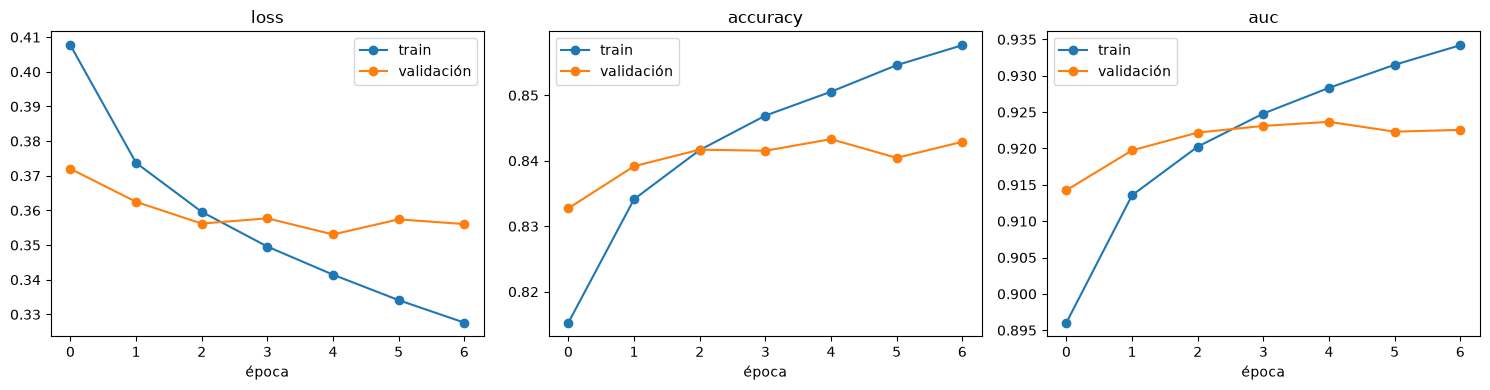

In [13]:
hist = history.history
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metrica in zip(axes, ["loss", "accuracy", "auc"]):
    ax.plot(hist[metrica], marker="o", label="train")
    ax.plot(hist[f"val_{metrica}"], marker="o", label="validación")
    ax.set_title(metrica)
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

# Evaluación

Evaluamos sobre el conjunto de test, que el modelo no ha visto ni en el entrenamiento de word2vec ni en el del clasificador. Usamos un umbral de 0.5 sobre la probabilidad de la sigmoide para decidir la clase

Test  -> loss: 0.3546 | accuracy: 0.8435 | AUC: 0.9230
              precision    recall  f1-score   support

    negativo     0.8326    0.8599    0.8460    120000
    positivo     0.8551    0.8271    0.8409    120000

    accuracy                         0.8435    240000
   macro avg     0.8438    0.8435    0.8434    240000
weighted avg     0.8438    0.8435    0.8434    240000



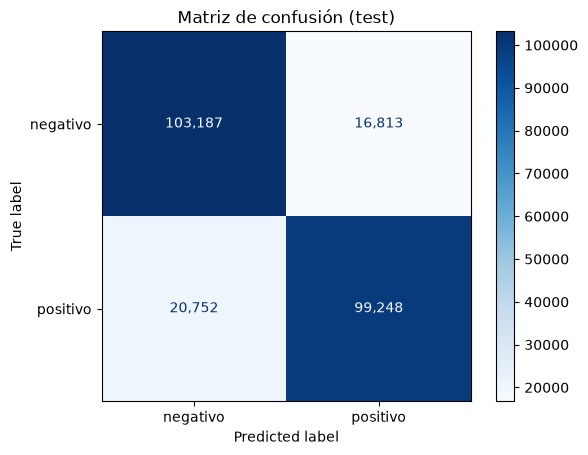

In [14]:
test_loss, test_acc, test_auc = model.evaluate(ds_test, verbose=0)
print(f"Test  -> loss: {test_loss:.4f} | accuracy: {test_acc:.4f} | AUC: {test_auc:.4f}")

y_true = df_test["label"].to_numpy()
y_prob = model.predict(ds_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=["negativo", "positivo"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=["negativo", "positivo"]).plot(cmap="Blues", values_format=",")
plt.title("Matriz de confusión (test)")
plt.show()

### Análisis de errores

Vemos los tuits en los que el modelo se equivoca con más seguridad. Suele tratarse de ironía, de etiquetas ruidosas (recordemos que la etiqueta viene del emoticono, no de una persona) o de frases cuyo sentimiento depende de contexto externo.

In [15]:
errores = df_test.assign(prob=y_prob, pred=y_pred)
errores = errores[errores["pred"] != errores["label"]]
errores = errores.assign(confianza=(errores["prob"] - 0.5).abs()).sort_values("confianza", ascending=False)

pd.set_option("display.max_colwidth", 120)
print(errores[["text", "label", "prob"]].head(10))

                                                                                                                       text  \
1413397                                                     So sick so sick of being tired, and oh so tired of being sick.    
1162588                                                                      Got the worst headache like, ever!    unhappy.   
685580                                                  @chemix00 um hello, simpsons quote! you're usually so good at that    
717568                                    @yelyahwilliams  you are awsome and such an inspiration! good lock and god bless!   
1179970  Rt @kellypuffs: why, oh WHY, does my hotel room smell like a dentist's office?!?  &lt;--- Here's the  BAD news...    
1441763                                                                         @BARACKOKITTY my throat feels so injured..    
340897                                                                        In the yard  woooooo just had a l

# Predicción sobre frases nuevas

Para clasificar texto nuevo aplicamos exactamente el mismo pipeline: `preprocess` → unir tokens → `vectorizator` → modelo.

In [16]:
def predecir(textos):
    tokens = [" ".join(preprocess(t)) for t in textos]
    probs = model.predict(vectorizator(tf.constant(tokens)), verbose=0).ravel()
    for texto, p in zip(textos, probs):
        etiqueta = "positivo" if p >= 0.5 else "negativo"
        print(f"{p:.3f}  {etiqueta:<8}  {texto}")

predecir([
    "I love love movies",
    "I can't believe how bad this day was :(",
    "just got my new phone, sooo happy!!!",
    "I don't hate it, it's actually not bad",
    "worst customer service ever, never again",
    "@john thanks for the help yesterday <3",
])

0.987  positivo  I love love movies
0.141  negativo  I can't believe how bad this day was :(
0.998  positivo  just got my new phone, sooo happy!!!
0.574  positivo  I don't hate it, it's actually not bad
0.011  negativo  worst customer service ever, never again
0.948  positivo  @john thanks for the help yesterday <3
